# std::variant - notebook demonstracyjny (C++17)

Materiał prowadzi od podstaw `std::variant` do praktycznych zastosowań.
## Jak korzystać

Do wykonania potrzebujesz Jupyter Notebook/JupyterLab lub obsługi notebooków w VS Code, kernela **Python 3 (ipykernel)** oraz lokalnego kompilatora i biblioteki standardowej C++17. Sam Python nie zastępuje kompilatora C++. Wybierz kernel Python 3 i uruchom wszystkie komórki od góry. Pierwsza komórka techniczna rejestruje `%%cpp`; kolejne zawierają kod C++.

Każda komórka `%%cpp` jest osobnym, kompletnym programem z własnym `main()`. Nie współdzieli zmiennych ani deklaracji z innymi komórkami. Po edycji uruchom ponownie tę samą komórkę. Także krótkie przykłady zawierają potrzebne nagłówki, definicje typów i `main()`, więc można je uruchamiać niezależnie po wykonaniu komórki przygotowującej.

Domyślnie używany jest kompilator `c++` z PATH. Aby go zmienić, ustaw `CXX` w środowisku przed uruchomieniem Jupytera albo zmień `COMPILER_NAME` w komórce technicznej. Podaj nazwę lub ścieżkę samego programu, bez flag. W Windows można wybrać `g++` lub `clang++` (kompilator MSVC `cl` używa innych flag i nie jest obsługiwany przez ten pomocnik). Na macOS Homebrew GCC może wymagać ustawienia `SDKROOT`, jak opisano w README.

## Przygotowanie wykonania

Ta komórka Python definiuje polecenie `%%cpp`. Zapisuje źródło i plik wykonywalny w katalogu tymczasowym, kompiluje z ostrzeżeniami, wykonuje program i usuwa pliki. Błędy kompilatora i programu są pokazywane pod komórką. Dwie celowo błędne demonstracje w dodatku używają `%%cpp --expect-error`: pokazują początek komunikatu kompilatora i pozwalają kontynuować wykonanie notebooka. Jeśli taki program skompiluje się poprawnie, notebook zgłosi błąd zamiast uznać demonstrację za udaną. Limit kompilacji wynosi 60 sekund, a wykonania 10 sekund.


In [3]:
import os
import shutil
import subprocess
from pathlib import Path
from tempfile import TemporaryDirectory

from IPython.core.magic import register_cell_magic

COMPILER_NAME = os.environ.get("CXX", "c++")

@register_cell_magic
def cpp(line: str, cell: str) -> None:
    """Kompiluje i uruchamia jedną niezależną demonstrację C++17."""
    option = line.strip()
    if option not in {"", "--expect-error"}:
        raise ValueError("Użyj %%cpp albo %%cpp --expect-error.")
    expect_error = option == "--expect-error"
    compiler = shutil.which(COMPILER_NAME)
    if compiler is None:
        raise RuntimeError(
            f"Nie znaleziono kompilatora {COMPILER_NAME!r}. "
            "Zainstaluj kompilator C++17 lub ustaw COMPILER_NAME."
        )
    with TemporaryDirectory(prefix="variant-notebook-") as directory:
        source = Path(directory) / "example.cpp"
        executable = Path(directory) / ("example.exe" if os.name == "nt" else "example")
        source.write_text(cell, encoding="utf-8")
        compiled = subprocess.run(
            [compiler, "-std=c++17", "-Wall", "-Wextra", "-Wpedantic", "-Werror",
             str(source), "-o", str(executable)],
            capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=60,
        )
        if expect_error:
            if compiled.returncode == 0:
                raise RuntimeError("Oczekiwano błędu kompilacji, ale program skompilował się poprawnie.")
            print("Oczekiwany błąd kompilacji. Początek komunikatu kompilatora:")
            diagnostics = (compiled.stdout + compiled.stderr).replace(str(source), "example.cpp").splitlines()
            print("\n".join(diagnostics[:16]))
            if len(diagnostics) > 16:
                print("[Dalsza część komunikatu została pominięta.]")
            return
        if compiled.returncode != 0:
            raise RuntimeError("Błąd kompilacji:\n" + compiled.stdout + compiled.stderr)
        executed = subprocess.run(
            [str(executable)], capture_output=True, text=True,
            encoding="utf-8", errors="replace", timeout=10,
        )
        print(executed.stdout, end="")
        if executed.stderr:
            print(executed.stderr, end="")
        if executed.returncode != 0:
            raise RuntimeError(f"Program zakończył się kodem {executed.returncode}.")

print(f"Gotowe: %%cpp używa {COMPILER_NAME}, standard C++17.")

Gotowe: %%cpp używa c++, standard C++17.


## A. Podstawy: po co i jak?


### 1. Co daje `std::variant`?

Zwykła zmienna ma jeden ustalony typ. Na przykład `int wynik = 42;` przechowuje liczbę całkowitą. Nie możesz później przypisać do niej tekstu `"brak wyniku"`.

Załóżmy jednak, że piszesz program obsługujący ustawienia aplikacji. Jedno ustawienie jest liczbą, np. liczba prób połączenia `3`. Inne jest tekstem, np. nazwa serwera `"localhost"`. Chcesz mieć wspólny typ, którym możesz opisać **wartość pojedynczego ustawienia**.

`std::variant` pozwala zadeklarować taki typ:


In [4]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};

    std::cout << std::get<int>(wartosc) << '\n';
}


42


Przeczytaj deklarację `wartosc` tak: **„Zmienna `wartosc` może przechowywać liczbę typu `int` albo tekst typu `std::string`. Na początku przechowuje liczbę 42”.**

Rozłóżmy zapis na części:

- `std::variant` to narzędzie z biblioteki standardowej C++.
- `<int, std::string>` to lista dozwolonych typów. Ustalasz ją przy deklaracji.
- `wartosc` to nazwa zmiennej.
- `{42}` podaje początkową wartość.

W takim wariancie przechowujesz **jedną wartość naraz**. Gdy zapiszesz tekst, zastąpi on poprzednią liczbę.


In [5]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42}; // teraz liczba
    wartosc = std::string{"localhost"}; // teraz tekst

    std::cout << std::get<std::string>(wartosc) << '\n';
}


localhost


`std::string{"localhost"}` tworzy obiekt typu `std::string` z podanego tekstu. Dzięki jawnemu zapisowi widać, który typ chcemy umieścić w wariancie.

**Typ samej zmiennej `wartosc` się nie zmienia:** cały czas jest to `std::variant<int, std::string>`. Zmienia się to, który z dwóch dozwolonych typów jest w niej aktualnie przechowywany.

Każdy typ z listy nazywamy **alternatywą**. „Aktywna alternatywa” oznacza po prostu typ przechowywany w tej chwili: najpierw `int`, potem `std::string`.

#### Dlaczego nie zapisać po prostu dwóch pól?

Można stworzyć strukturę z polami `int liczba`, `std::string tekst` i dodatkową informacją, z którego pola należy korzystać. Wtedy oba pola istnieją jednocześnie, a programista musi pilnować tej dodatkowej informacji.

`variant` sam pamięta, którą wartość przechowuje, i kontroluje dostęp do niej. Nie musisz osobno utrzymywać flagi „teraz używamy tekstu”. W części B wykorzystamy to do przechowywania ustawień oraz wyniku operacji: sukcesu albo błędu.


### 2. Pierwszy program: zapis i odczyt

Zacznijmy od niewielkiego programu pokazującego zapis i odczyt wartości. Uruchom poniższą komórkę, aby zobaczyć liczbę, a następnie zastępujący ją tekst.


In [6]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    std::cout << std::get<int>(wartosc) << '\n';

    wartosc = std::string{"localhost"};
    std::cout << std::get<std::string>(wartosc) << '\n';
}


42
localhost


Nagłówek `<variant>` udostępnia `std::variant` i funkcje dostępu do wartości. `<string>` jest potrzebny dla `std::string`, a `<iostream>` do wypisywania.

Zwróć uwagę na dwie operacje:

1. **Zapis:** `wartosc = std::string{"localhost"};` zastępuje liczbę tekstem.
2. **Odczyt:** `std::get<std::string>(wartosc)` pobiera przechowywany tekst.

W zapisie `std::get<int>(wartosc)` część `<int>` oznacza: **„chcę odczytać liczbę typu `int`”**. Nie jest to polecenie zamiany tekstu na liczbę. Jeśli w środku jest tekst, taki odczyt się nie powiedzie. Za chwilę pokażemy, jak to sprawdzać.

`get` daje dostęp przez referencję do wartości znajdującej się w wariancie. W powyższym programie po prostu przekazujemy ją do `std::cout`.

#### Numer przechowywanego typu: `index()`

Typy na liście są ponumerowane od zera. Dla `std::variant<int, std::string>`:

- indeks **0** oznacza `int`;
- indeks **1** oznacza `std::string`.


In [7]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    std::cout << wartosc.index() << '\n'; // 0
    wartosc = std::string{"localhost"};
    std::cout << wartosc.index() << '\n'; // 1
}


0
1


Możesz też użyć numeru do odczytu: `std::get<0>(wartosc)` wybiera pierwszą alternatywę, a `std::get<1>(wartosc)` drugą. Numer oznacza **pozycję typu na liście**, nie przechowywaną liczbę. Zwykle zapis przez typ, np. `get<std::string>`, łatwiej zrozumieć.

#### Inny sposób zapisania wartości: `emplace`

Przypisanie, które już znasz, wystarczy w wielu sytuacjach. `emplace` pozwala wskazać typ i przekazać argumenty do utworzenia nowej wartości bezpośrednio w wariancie:


In [8]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    wartosc.emplace<std::string>("localhost");
    std::cout << std::get<std::string>(wartosc) << '\n'; // localhost
}


localhost


Tutaj `emplace<std::string>("localhost")` zastępuje dotychczasową liczbę nowym tekstem. Po tej operacji poprzedniej liczby 42 już w wariancie nie ma.

#### Co się stanie bez podania wartości początkowej?


In [9]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc;
    std::cout << std::get<int>(wartosc) << '\n'; // 0
}


0


Wariant zaczyna od **pierwszego typu z listy**. W tym przypadku jest to `int` o wartości 0. Nie zaczyna jako „pusty”. Jeżeli pierwszy typ nie pozwala na utworzenie obiektu bez argumentów, taka deklaracja nie będzie dostępna. Rozwiązanie tego przypadku omawiamy w części C.

W komórce demonstracyjnej poniżej dodajemy trzeci typ: `double`, czyli liczbę zmiennoprzecinkową. Wariant ma kolejność typów `int, double, std::string`, dlatego tekst ma indeks 2, a liczba zmiennoprzecinkowa - indeks 1. Wynik pojawia się bezpośrednio pod wykonywalną komórką.

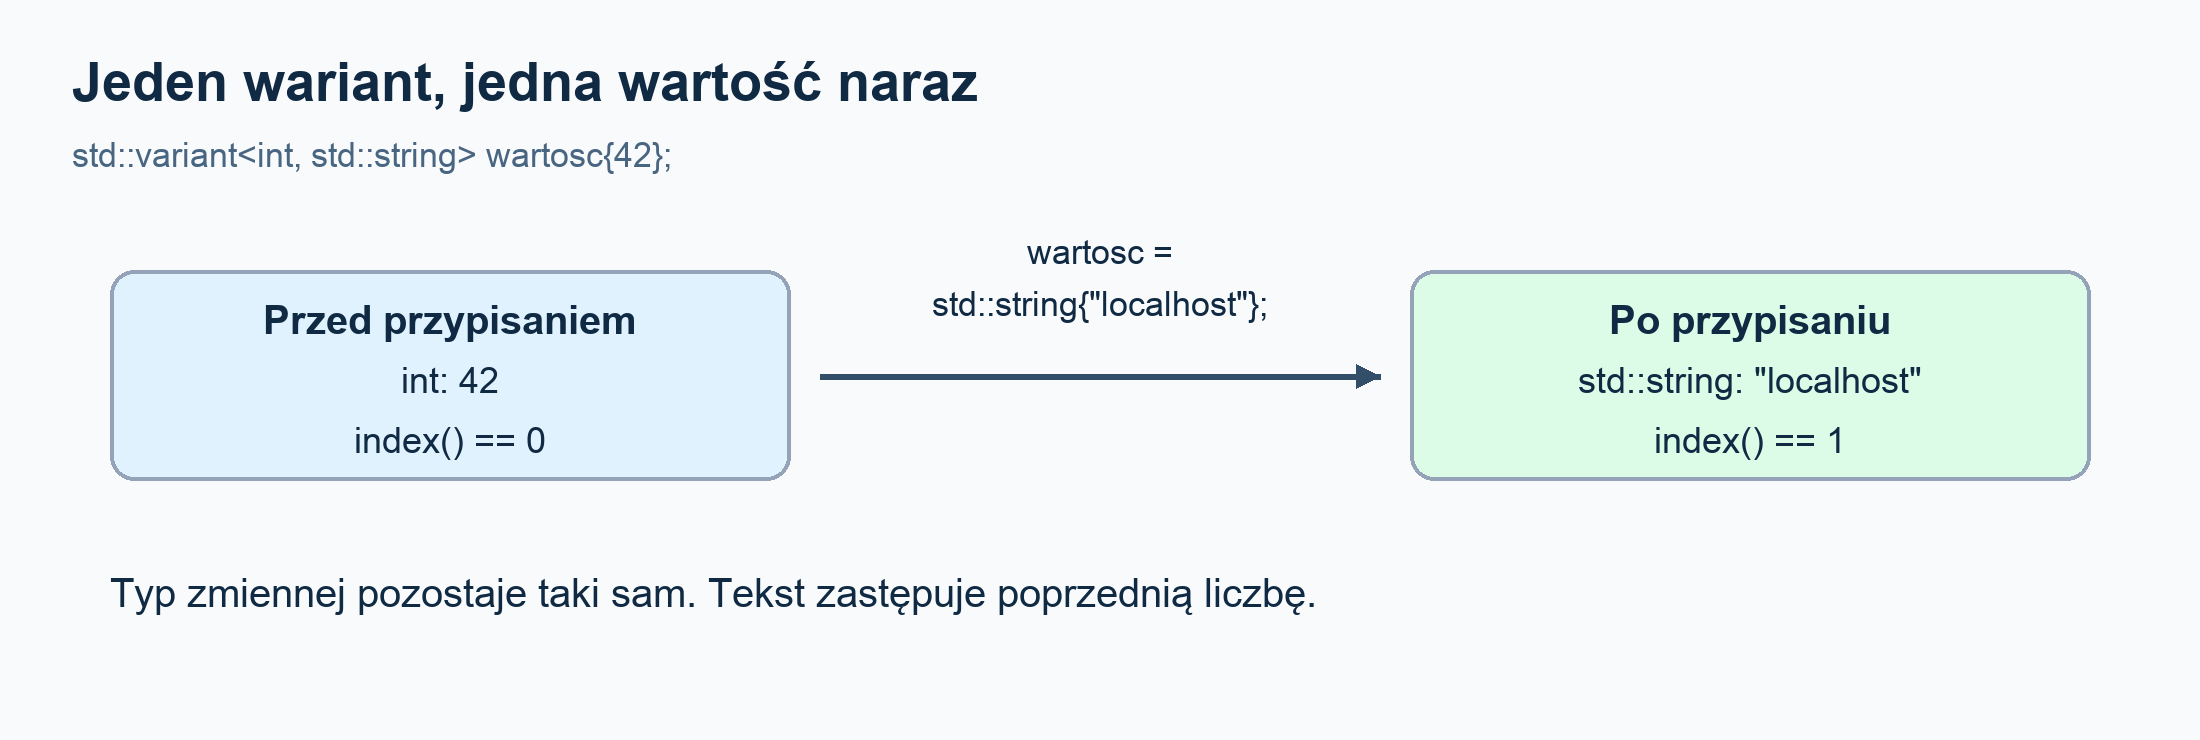

Diagram pokazuje wariant z dwoma typami z wprowadzenia. Demonstracja poniżej rozszerza tę listę o `double`, dlatego indeks tekstu jest w niej inny.


#### Demonstracja: Zmiana wartości i indeksu

Kompletna komórka pokazuje kolejno `int`, `std::string` i `double`. Uruchom ją, aby zobaczyć wartość oraz indeks po każdej zmianie.


In [10]:
%%cpp
// Cel: zmiana aktywnej alternatywy bez osobnej flagi typu.
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, double, std::string> value{42};
    std::cout << "int: " << std::get<int>(value) << ", index: " << value.index() << '\n';
    value = std::string{"tekst"};
    std::cout << "string: " << std::get<2>(value) << ", index: " << value.index() << '\n';
    value.emplace<double>(3.5);
    std::cout << "double: " << std::get<double>(value) << ", index: " << value.index() << '\n';
}


int: 42, index: 0
string: tekst, index: 2
double: 3.5, index: 1


**Jak czytać wynik:** Wynik pokazuje kolejno liczbę całkowitą, tekst i liczbę zmiennoprzecinkową. Indeksy wynikają z kolejności `int, double, std::string`.


### 3. Skąd wiedzieć, co jest w środku?

Załóżmy, że otrzymujesz wariant od innej części programu. Nie wiesz, czy przechowuje liczbę, czy tekst. Masz trzy przydatne narzędzia.

#### `holds_alternative`: sprawdź typ

`std::holds_alternative<int>(wartosc)` odpowiada na pytanie: **„Czy w tej chwili w środku jest `int`?”**. Wynikiem jest `true` albo `false`.


In [9]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    if (std::holds_alternative<int>(wartosc)) {
        std::cout << std::get<int>(wartosc) << '\n'; // 42
    }
}


42


Najpierw sprawdzamy typ, a potem odczytujemy pasującą wartość. Samo `holds_alternative` niczego nie pobiera ani nie zmienia.

#### `get_if`: spróbuj uzyskać dostęp do wartości

`std::get_if<int>(&wartosc)` próbuje uzyskać dostęp do liczby. Zwraca **wskaźnik do liczby**, jeśli jest ona w środku. Jeżeli w środku jest tekst, zwraca `nullptr`, czyli pusty wskaźnik.


In [11]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    int* liczba = std::get_if<int>(&wartosc);

    if (liczba != nullptr) {
        std::cout << *liczba << '\n'; // 42
    } else {
        std::cout << "W środku nie ma liczby\n";
    }
}


42


Znaczenie symboli w tym przykładzie:

- `&wartosc` przekazuje adres wariantu - tego wymaga `get_if`.
- `int* liczba` deklaruje wskaźnik do `int`.
- `liczba != nullptr` sprawdza, czy uzyskaliśmy dostęp do liczby.
- `*liczba` odczytuje wartość spod wskaźnika. Robimy to dopiero po sprawdzeniu, że wskaźnik nie jest pusty.

Jeżeli w pierwszej linii wpiszesz `std::string{"localhost"}` zamiast `42`, wykona się gałąź `else`. `get_if` nie rzuca wyjątku tylko dlatego, że w środku jest inny dozwolony typ.

#### `get`: odczytaj albo otrzymaj wyjątek

`get` już poznaliśmy. Gdy prosisz o typ, który jest na liście, ale nie jest teraz przechowywany, rzuca wyjątek `std::bad_variant_access`.


In [11]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    try {
        std::cout << std::get<std::string>(wartosc) << '\n';
    } catch (const std::bad_variant_access&) {
        std::cout << "Nie mozna odczytac tekstu: w srodku jest liczba\n";
    }
}


Nie mozna odczytac tekstu: w srodku jest liczba


`try` obejmuje operację, która może rzucić wyjątek. `catch` przechwytuje wskazany rodzaj wyjątku, dzięki czemu ten program wypisze komunikat zamiast zakończyć się z nieobsłużonym wyjątkiem.

**Którego narzędzia użyć?** Gdy chcesz tylko sprawdzić typ, wybierz `holds_alternative`. Gdy inny typ jest spodziewaną sytuacją i potrzebujesz wartości, wygodne jest `get_if`. `get` daje bezpośredni dostęp z kontrolą przez wyjątek, jeśli wybrana alternatywa nie pasuje.

Komórka demonstracyjna poniżej zestawia wszystkie trzy narzędzia: sprawdzenie typu przez `holds_alternative`, próbę odczytu przez `get_if` oraz odczyt przez `get` z przechwyceniem wyjątku. Po zmianie wartości na tekst pokazuje też udany odczyt przez wskaźnik.

#### Dwie rzeczy, na które trzeba uważać

**Typ musi być na liście.** Dla `std::variant<int, std::string>` próba użycia `std::get<double>` jest błędem kompilacji, bo `double` nie jest dozwoloną alternatywą. Tego błędu nie przechwycisz przez `catch`: program nie zostanie zbudowany. Ta sama zasada dotyczy `get_if` i `holds_alternative`.

**Nie zachowuj dostępu do starej wartości po jej zniszczeniu.** Jeśli `get_if` zwróci wskaźnik do liczby, a później zastąpisz ją tekstem, nie wolno już używać tego wskaźnika do odczytu poprzedniej liczby. Dotyczy to także referencji uzyskanej przez `get`.

W części C poznasz szczególny przypadek, w którym wyjątek podczas zmiany wartości może pozostawić wariant bez żadnej wartości. Na razie pracowaliśmy z wariantami zawierającymi liczbę lub tekst.

**Przed przejściem dalej:** wiesz już, jak zadeklarować dozwolone typy, zapisać jedną z wartości i bezpiecznie ją odczytać. W części B pokażemy `std::visit`, które pozwala opisać operację dla każdego typu bez ręcznego sprawdzania go w kolejnych instrukcjach `if`.


#### Demonstracja: Trzy sposoby dostępu do wartości

Wykonaj komórkę, aby zobaczyć różnicę między sprawdzeniem typu, pustym wskaźnikiem i przechwyconym wyjątkiem.


In [12]:
%%cpp
// Cel: odróżnienie odczytu rzucającego wyjątek od sprawdzania wskaźnika.
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> value{7};
    std::cout << "get<int>: " << std::get<int>(value) << '\n';
    std::cout << std::boolalpha << "holds string: " << std::holds_alternative<std::string>(value) << '\n';
    if (std::get_if<std::string>(&value) == nullptr) {
        std::cout << "get_if<string>: nullptr\n";
    }
    try {
        (void)std::get<std::string>(value);
    } catch (const std::bad_variant_access&) {
        std::cout << "get<string>: bad_variant_access\n";
    }
    value = std::string{"gotowe"};
    if (const auto* text = std::get_if<std::string>(&value)) {
        std::cout << "get_if<string>: " << *text << '\n';
    }
}


get<int>: 7
holds string: false
get_if<string>: nullptr
get<string>: bad_variant_access
get_if<string>: gotowe


**Jak czytać wynik:** Najpierw aktywny jest `int`: sprawdzenie tekstu daje `false`, `get_if` zwraca `nullptr`, a `get` rzuca przechwycony wyjątek. Po przypisaniu tekstu odczyt przez wskaźnik się udaje.


## B. Przetwarzanie i praktyka


### 4. `std::visit`: operacja dla aktywnej alternatywy

Seria `if (holds_alternative<...>)` szybko się rozrasta. `std::visit(f, v)` wywołuje `f` z aktualnie przechowywaną wartością. Sama funkcja nie musi ręcznie sprawdzać indeksu.


In [13]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> v{12};
    std::visit(
        [](const auto& x) {
            std::cout << x;
        },
        v
    );

    std::cout << '\n';
}


12


`[]` zaczyna lambdę - niewielki obiekt zachowujący się jak funkcja. Puste nawiasy oznaczają brak przechwytywania zmiennych z otoczenia. Parametr `const auto&` oznacza referencję bez kopiowania i modyfikacji; `auto` sprawia, że operator wywołania lambdy jest szablonem dopasowywanym do typu argumentu.

Odwiedzający musi dać się wywołać dla **każdej alternatywy**, a nie tylko tej aktywnej przy konkretnym uruchomieniu. Dla powyższego kodu każdy możliwy typ musi obsługiwać wypisywanie przez `<<`.

Następna komórka odróżnia tekst od liczby wewnątrz lambdy `describe`. Wywołuje ją raz dla liczby 12, a raz dla tekstu `kot`:


In [14]:
%%cpp
#include <iostream>
#include <string>
#include <variant>
#include <type_traits>

int main() {
    const auto describe = [](const auto& item) {
        using T = std::decay_t<decltype(item)>;
        if constexpr (std::is_same_v<T, std::string>) {
            std::cout << item.size();
        } else {
            std::cout << item + 1;
        }
        std::cout << '\n';
    };
    describe(12);
    describe(std::string{"kot"});
}


13
3


`decltype(item)` odczytuje typ parametru, np. `const std::string&`. Dla użytych typów `std::decay_t` usuwa referencję i kwalifikator `const`. `std::is_same_v` porównuje typy. `if constexpr` wybiera gałąź podczas instancjowania szablonu: gałąź z `.size()` nie musi być poprawna dla `int`. Zwykłe `if` nie daje tego efektu. W odrzucanej gałęzi nadal musi być poprawna składnia; nie jest to sposób ukrywania dowolnego błędu.


#### Demonstracja: Jedna operacja, różne typy

Komórka pokazuje wypisywanie obu typów oraz wybór działania przez `if constexpr`.


In [15]:
%%cpp
// Cel: jedna operacja dla każdej alternatywy oraz rozgałęzienie w kompilacji.
#include <iostream>
#include <string>
#include <type_traits>
#include <variant>

int main() {
    std::variant<int, std::string> value{12};
    const auto print = [](const auto& item) {
        std::cout << "wartosc: " << item << '\n';
    };
    const auto describe = [](const auto& item) {
        using T = std::decay_t<decltype(item)>;
        if constexpr (std::is_same_v<T, std::string>) {
            std::cout << "dlugosc: " << item.size() << '\n';
        } else {
            std::cout << "liczba + 1: " << item + 1 << '\n';
        }
    };
    std::visit(print, value);
    std::visit(describe, value);
    value = std::string{"kot"};
    std::visit(print, value);
    std::visit(describe, value);
}


wartosc: 12
liczba + 1: 13
wartosc: kot
dlugosc: 3


**Jak czytać wynik:** Dla liczby wykonywane jest dodawanie, a dla tekstu obliczenie długości. `if constexpr` pozwala pominąć niepasującą gałąź podczas tworzenia konkretnej instancji lambdy.


### 5. `overloaded`: kilka lambd jako jeden odwiedzający

Czasem czytelniej napisać oddzielną funkcję dla każdego typu. W C++17 można połączyć lambdy tak:


In [16]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

template <class... Ts>
struct overloaded : Ts... {
    using Ts::operator()...;
};
template <class... Ts>
overloaded(Ts...) -> overloaded<Ts...>;

int main() {
    const auto print = overloaded{
        [](int x) {
            std::cout << "liczba: " << x << '\n';
        },
        [](const std::string& x) {
            std::cout << "tekst: " << x << '\n';
        }
    };
    print(42);
    print(std::string{"kot"});
}


liczba: 42
tekst: kot


`Ts...` to lista typów. Struktura dziedziczy po obiektach funkcyjnych, a `using` udostępnia wszystkie ich operatory wywołania. Deklaracja `overloaded(Ts...) -> overloaded<Ts...>` jest wskazówką dedukcji: pozwala kompilatorowi wywnioskować typy lambd z argumentów. Jest potrzebna w tym zapisie dla C++17. To **nasz pomocniczy szablon**, nie część biblioteki standardowej.


In [17]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

template <class... Ts>
struct overloaded : Ts... {
    using Ts::operator()...;
};
template <class... Ts>
overloaded(Ts...) -> overloaded<Ts...>;

int main() {
    std::variant<int, std::string> v{std::string{"kot"}};
    std::visit(
        overloaded{
            [](int x) {
                std::cout << "liczba: " << x;
            },
            [](const std::string& x) {
                std::cout << "tekst: " << x;
            }
        },
        v
    );

    std::cout << '\n';
}


tekst: kot


Demonstracja poniżej rozszerza obsługę o `double`, a następnie pokazuje odwiedzającego, który zamienia każdą wartość na `std::string`.

W C++17 wszystkie możliwe wywołania w jednym `std::visit` muszą mieć ten sam typ wyniku i tę samą kategorię wartości. `int` w jednym przypadku i `double` w drugim nie wystarczą, nawet jeśli jedno konwertuje się do drugiego. W poniższej demonstracji jawne `-> std::string` zapewnia wspólny wynik. Przy wypisywaniu wszystkie gałęzie zwracają `void`.

Pułapka: przeciążenia dopuszczają konwersje. Jeśli usuniesz obsługę `int`, funkcja przyjmująca `double` może nadal go przyjąć. Ogólna lambda `auto` również może obsłużyć nowo dodany typ. Kompilator sprawdza poprawność wywołania, a nie to, czy świadomie zaprojektowałeś obsługę każdego przypadku.

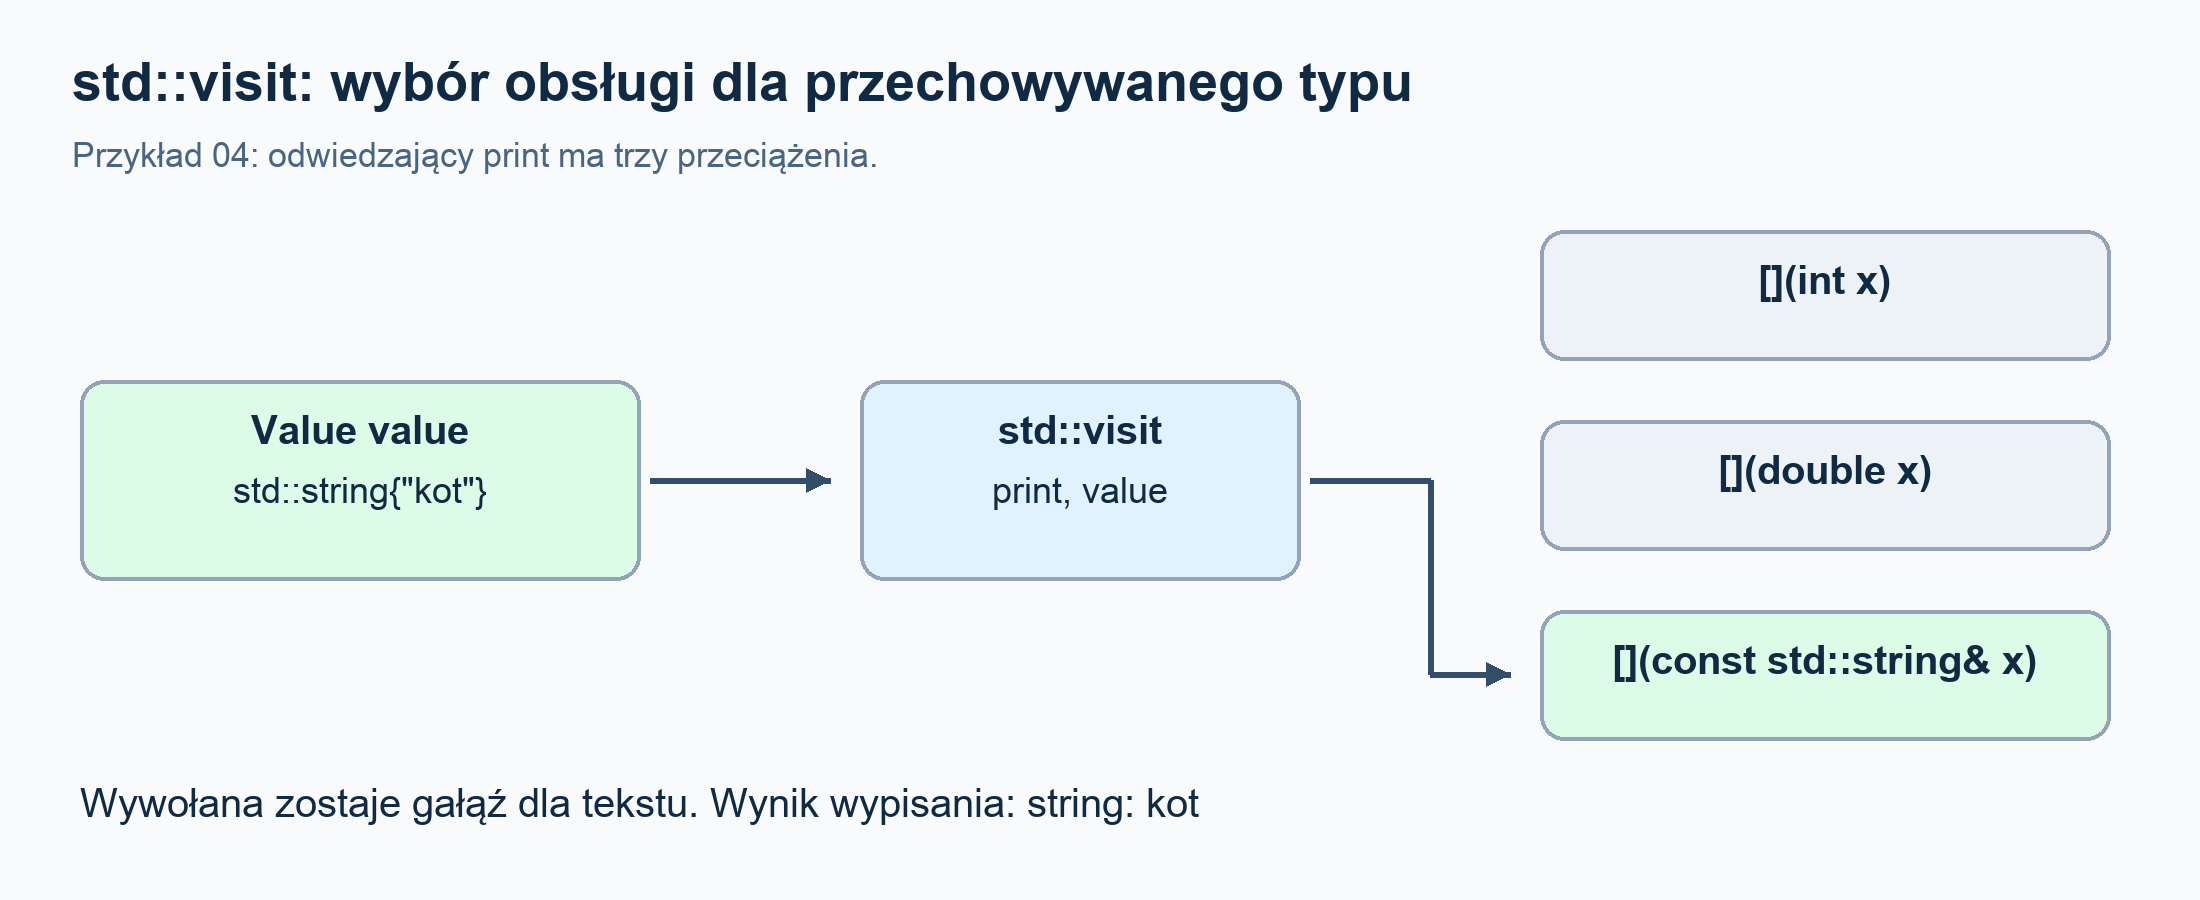

Wszystkie trzy gałęzie odwiedzającego muszą być poprawne, choć pojedyncze wywołanie `visit` wybiera jedną z nich.


#### Demonstracja: Osobne lambdy i wspólny typ wyniku

Pierwszy odwiedzający wypisuje wartości, a drugi buduje ich tekstowe opisy i pozwala odczytać długości tych opisów.


In [18]:
%%cpp
// Cel: osobne przeciążenia i jawny wspólny typ wyniku odwiedzającego.
#include <iostream>
#include <sstream>
#include <string>
#include <variant>

template <class... Ts>
struct overloaded : Ts... {
    using Ts::operator()...;
};
template <class... Ts>
overloaded(Ts...) -> overloaded<Ts...>;

int main() {
    using Value = std::variant<int, double, std::string>;
    const auto print = overloaded{
        [](int x) {
            std::cout << "int: " << x << '\n';
        },
        [](double x) {
            std::cout << "double: " << x << '\n';
        },
        [](const std::string& x) {
            std::cout << "string: " << x << '\n';
        }
    };
    const auto as_text = [](const auto& x) -> std::string {
        std::ostringstream out;
        out << x;
        return out.str();
    };
    const Value values[] = {Value{4}, Value{2.5}, Value{std::string{"kot"}}};
    for (const auto& value : values) {
        std::visit(print, value);
    }
    std::cout << "dlugosci opisow:";
    for (const auto& value : values) {
        std::cout << ' ' << std::visit(as_text, value).size();
    }
    std::cout << '\n';
}


int: 4
double: 2.5
string: kot
dlugosci opisow: 1 3 3


**Jak czytać wynik:** Wypisywanie wybiera jedno z trzech przeciążeń. Drugi odwiedzający zwraca zawsze `std::string`, dlatego można następnie odczytać długość każdego opisu.


### 6. Zastosowanie: konfiguracja

Poniższa demonstracja przechowuje ustawienia w `std::map<std::string, ConfigValue>`. Każdy wpis ma nazwę i jedną wartość, a odwiedzający wypisuje ją niezależnie od aktywnego typu.

Jawne `std::string{"localhost"}` pokazuje zamierzony typ, bez polegania na szczegółach konwersji literału tekstowego. Mapa zapewnia tutaj kolejność po kluczach; `variant` nie odpowiada za kolejność wpisów.

Taki model zapobiega niezgodności ręcznej flagi i typu wartości. **Nie sprawdza jednak reguł konfiguracji:** nadal można przypisać tekst do klucza `retries`. Regułę „ten klucz wymaga liczby nieujemnej” trzeba zrealizować osobno. Dla z góry ustalonego zestawu ustawień zwykła struktura z nazwanymi polami może być lepsza.


#### Demonstracja: Ustawienia o różnych typach

Wykonaj komórkę, aby zobaczyć wspólne wypisywanie ustawień logicznych, liczbowych i tekstowych.


In [19]:
%%cpp
// Cel: konfiguracja z zamkniętym zbiorem typów i deterministyczną kolejnością.
#include <iostream>
#include <map>
#include <string>
#include <variant>

int main() {
    using ConfigValue = std::variant<bool, int, std::string>;
    const std::map<std::string, ConfigValue> config{
        {"debug", true}, {"retries", 3}, {"server", std::string{"localhost"}}
    };
    std::cout << std::boolalpha;
    for (const auto& entry : config) {
        std::cout << entry.first << " = ";
        std::visit(
            [](const auto& x) {
                std::cout << x;
            },
            entry.second
        );
        std::cout << '\n';
    }
}


debug = true
retries = 3
server = localhost


**Jak czytać wynik:** Każdy wpis konfiguracji ma ten sam typ `ConfigValue`, ale przechowuje inną alternatywę. `std::map` porządkuje klucze, a `boolalpha` wypisuje wartość logiczną jako `true`.


### 7. Zastosowanie: sukces albo błąd

W demonstracji parsera poniżej wynik operacji ma postać:


In [19]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

struct Success {
    int value;
};
struct Error {
    std::string message;
};
using Result = std::variant<Success, Error>;

int main() {
    Result wynik{Success{42}};
    std::cout << std::get<Success>(wynik).value << '\n';
    wynik = Error{"brak cyfr"};
    std::cout << std::get<Error>(wynik).message << '\n';
}


42
brak cyfr


Zamiast utrzymywać liczbę, flagę sukcesu i komunikat w trzech niezależnych polach, zwracamy jednoznaczny przypadek. Odwiedzający dostaje wartość sukcesu albo opis błędu.

Program używa `std::stoi`: przechwytuje brak poprawnej liczby oraz przekroczenie zakresu, a dodatkowo sprawdza liczbę zużytych znaków. Dzięki temu `12x` nie zostaje zaakceptowane jako pełny zapis liczby 12.

To celowo niewielki parser: dziedziczy akceptowanie początkowych białych znaków i znaku `+`/`-` z `stoi`; końcowe znaki, również spacje, odrzuca. Nie służy do definiowania uniwersalnego formatu liczb.

Zwracanie `Result` opisuje przewidywane wyniki operacji, ale nie daje gwarancji braku wszelkich wyjątków - np. tworzenie tekstu błędu może wymagać alokacji. W C++23 istnieje `std::expected<T, E>` przeznaczone do modelu wartość albo błąd; w tym pakiecie pozostajemy przy C++17.


#### Demonstracja: Sukces i trzy rodzaje błędów

Komórka przetwarza poprawną liczbę, tekst bez cyfr, liczbę z końcowymi znakami oraz wartość poza zakresem `int`.


In [21]:
%%cpp
// Cel: sukces i błąd jako rozłączne wyniki; parser akceptuje całe wejscie.
#include <iostream>
#include <stdexcept>
#include <string>
#include <variant>

struct Success {
    int value;
};
struct Error {
    std::string message;
};
using Result = std::variant<Success, Error>;

template <class... Ts>
struct overloaded : Ts... {
    using Ts::operator()...;
};
template <class... Ts>
overloaded(Ts...) -> overloaded<Ts...>;

Result parse_int(const std::string& input) {
    try {
        std::size_t consumed = 0;
        const int value = std::stoi(input, &consumed);
        if (consumed != input.size()) {
            return Error{"znaki po liczbie"};
        }
        return Success{value};
    } catch (const std::invalid_argument&) {
        return Error{"brak cyfr"};
    } catch (const std::out_of_range&) {
        return Error{"liczba poza zakresem int"};
    }
}

int main() {
    const std::string inputs[] = {"42", "abc", "12x", std::string(100, '9')};
    for (const auto& input : inputs) {
        const Result result = parse_int(input);
        std::visit(
            overloaded{
                [](const Success& s) {
                    std::cout << "sukces: " << s.value << '\n';
                },
                [](const Error& e) {
                    std::cout << "blad: " << e.message << '\n';
                }
            },
            result
        );
    }
}


sukces: 42
blad: brak cyfr
blad: znaki po liczbie
blad: liczba poza zakresem int


**Jak czytać wynik:** Wejście `42` daje sukces. `abc` nie zawiera liczby, `12x` pozostawia znaki po liczbie, a ciąg stu dziewiątek przekracza zakres `int`. Każdy błąd ma własny opis w alternatywie `Error`.


## C. Dla dociekliwych

Ta część rozwija podstawy z sekcji A i B. Zaczniemy od dwóch pytań: jak zapisać „jeszcze nie mam wartości” i co się dzieje, gdy ten sam typ występuje na liście dwa razy. Później przejdziemy do wyjątków, pamięci i maszyny stanów.


### 8. `monostate` i powtarzające się typy

#### Jak zapisać „jeszcze nic nie wybrano”?

Przypomnijmy: `std::variant<int, std::string> wartosc;` zaczyna od liczby 0. Czasem potrzebujesz jednak odróżnić „użytkownik podał zero” od „użytkownik jeszcze nic nie podał”.

Możesz dodać `std::monostate` jako pierwszą możliwość:


In [22]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<std::monostate, int, std::string> wartosc;
    std::cout << std::boolalpha << std::holds_alternative<std::monostate>(wartosc) << '\n'; // true

    wartosc = 0;
    std::cout << std::holds_alternative<int>(wartosc) << '\n'; // true
}


true
true


`std::monostate` to prosty typ bez danych, którym możesz oznaczyć „brak podanej wartości”. Wybierasz to znaczenie w swoim programie. W pierwszej chwili wariant przechowuje właśnie `monostate`; po przypisaniu zera przechowuje `int`.

**Wariant z `monostate` nadal ma aktywną alternatywę.** Jest nią `monostate`, w tym przykładzie o indeksie 0. To ważne rozróżnienie względem stanu po wyjątku z następnego podrozdziału.

#### Gdy typ wymaga argumentu konstruktora

Struktura `NoDefault` wymaga podania liczby przy tworzeniu obiektu. Poniższa komórka pokazuje jej definicję i użycie z `monostate`:


In [23]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

struct NoDefault {
    explicit NoDefault(int number) : value(number) {}
    int value;
};

int main() {
    std::variant<std::monostate, NoDefault> wartosc;
    wartosc.emplace<NoDefault>(7);
    std::cout << std::get<NoDefault>(wartosc).value << '\n'; // 7
}


7


Konstruktor `NoDefault(int number)` zapisuje przekazaną liczbę w polu `value`. `explicit` wymaga jawnego użycia tego konstruktora przy konwersji do `NoDefault`.

Deklaracja wariantu bez wartości początkowej działa, ponieważ pierwszym typem jest `monostate`, który można utworzyć bez argumentów. Dopiero `emplace<NoDefault>(7)` tworzy właściwy obiekt z liczbą 7 i zastępuje nim `monostate`.

Gdyby `NoDefault` był pierwszym typem, trzeba byłoby od razu podać argument jego konstruktora, np. przez `std::in_place_type<NoDefault>`:


In [24]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

struct NoDefault {
    explicit NoDefault(int number) : value(number) {}
    int value;
};

int main() {
    std::variant<NoDefault, std::string> wartosc{std::in_place_type<NoDefault>, 7};
    std::cout << std::get<NoDefault>(wartosc).value << '\n'; // 7
}


7


#### Czy ten sam typ może wystąpić dwa razy?

Tak, ale wtedy sama nazwa typu nie wystarcza do wybrania miejsca na liście:


In [25]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, int> wartosc{std::in_place_index<1>, 9};
    std::cout << wartosc.index() << '\n';      // 1
    std::cout << std::get<1>(wartosc) << '\n'; // 9
}


1
9


`std::in_place_index<1>` oznacza: „utwórz wartość w alternatywie o indeksie 1”, czyli w drugim `int`. Liczba 9 jest wartością, którą tam zapisujemy.

Próba `std::get<int>(wartosc)` byłaby błędem kompilacji: kompilator nie wie, o który z dwóch `int` chodzi. Taki sam problem dotyczy `get_if<int>` i `holds_alternative<int>`. Można używać `get<0>` i `get<1>`, a do sprawdzania wybranej pozycji - `index()`.

Jeśli dwie liczby mają różne znaczenie, lepiej wyrazić je w nazwach typów:


In [26]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

struct UserId {
    int value;
};
struct OrderId {
    int value;
};

int main() {
    std::variant<UserId, OrderId> identyfikator{OrderId{9}};
    std::cout << std::get<OrderId>(identyfikator).value << '\n'; // 9
}


9


Teraz widać, że odczytujemy identyfikator zamówienia, a nie dowolną liczbę z pozycji 1.


### 9. Co oznacza `valueless_by_exception()`?

Zwykle wariant zawiera jedną z dozwolonych wartości. Istnieje jednak szczególny przypadek: podczas zmiany wartości może wystąpić wyjątek, po którym **wariant nie zawiera żadnej alternatywy**.

Wyobraź sobie następujący przebieg:

1. Wariant przechowuje liczbę 42.
2. Program chce zastąpić ją obiektem innego typu.
3. Dotychczasowa liczba zostaje usunięta.
4. Tworzenie nowego obiektu kończy się wyjątkiem.
5. Nowego obiektu nie udało się utworzyć, a starej liczby już nie ma.

Metoda `valueless_by_exception()` pozwala sprawdzić, czy wariant jest w takim stanie. Zwraca wtedy `true`.

**Nie każdy wyjątek powoduje utratę wartości.** Powyższy przebieg tłumaczy problem; dokładny skutek zależy od wykonywanej operacji i typów. Samo wywołanie `get` z niewłaściwym typem rzuca wyjątek, ale nie usuwa przechowywanej wartości.

#### Jak wymuszamy ten przypadek w demonstracji?

W poniższej komórce typ `ThrowsOnMove` ma konstruktor przenoszący, który celowo rzuca wyjątek. Konstruktor przenoszący służy do tworzenia obiektu na podstawie innego obiektu, którego zasoby można przejąć. Zapis `noexcept(false)` jawnie zaznacza, że ten konstruktor może rzucać wyjątki.

Program przygotowuje dwa warianty:


In [27]:
%%cpp
#include <iostream>
#include <string>
#include <variant>
#include <stdexcept>
#include <utility>

struct ThrowsOnMove {
    ThrowsOnMove() = default;
    ThrowsOnMove(const ThrowsOnMove&) = default;
    ThrowsOnMove& operator=(const ThrowsOnMove&) = default;
    ThrowsOnMove(ThrowsOnMove&&) noexcept(false) {
        throw std::runtime_error{"move failed"};
    }
    ThrowsOnMove& operator=(ThrowsOnMove&&) = default;
};

int main() {
    using Value = std::variant<int, ThrowsOnMove>;
    Value target{42};
    Value source{std::in_place_index<1>};

    try {
        target = std::move(source);
    } catch (const std::runtime_error&) {
        std::cout << "wyjatek przy przenoszeniu\n";
    }
    std::cout << std::boolalpha << target.valueless_by_exception() << '\n'; // true
}


wyjatek przy przenoszeniu
true


Definicja `ThrowsOnMove` znajduje się w tej samej komórce, przed `main()`. `target` początkowo zawiera liczbę, a `source` - obiekt `ThrowsOnMove`. `in_place_index<1>` tworzy obiekt źródłowy bezpośrednio w drugiej alternatywie, bez wcześniejszego przenoszenia go z innego miejsca.

`std::move(source)` pozwala wybrać operację przenoszącą; samo wywołanie `std::move` jeszcze niczego nie przenosi. Przenoszenie odbywa się w przypisaniu. Ponieważ warianty zawierają różne typy, `target` musi utworzyć u siebie obiekt `ThrowsOnMove`. Jego konstruktor rzuca wyjątek.

**Dla tego konkretnego przypadku standard gwarantuje, że `target` zostanie bez wartości:** chodzi o wyjątek z konstrukcji przenoszącej podczas przypisania przenoszącego między wariantami o różnych aktywnych indeksach.

#### Co można wtedy zrobić?

Obiekt wariantu nadal istnieje, ale nie ma w nim wartości, którą można odczytać:

- `index()` zwraca specjalną stałą `std::variant_npos`, zamiast indeksu typu.
- `get_if` zwraca `nullptr`, a `holds_alternative` zwraca `false` dla każdego typu z listy.
- `get` i `visit` rzucają `std::bad_variant_access`.

Możesz nadać mu nową wartość:


In [28]:
%%cpp
#include <iostream>
#include <string>
#include <variant>
#include <stdexcept>
#include <utility>

struct ThrowsOnMove {
    ThrowsOnMove() = default;
    ThrowsOnMove(const ThrowsOnMove&) = default;
    ThrowsOnMove& operator=(const ThrowsOnMove&) = default;
    ThrowsOnMove(ThrowsOnMove&&) noexcept(false) {
        throw std::runtime_error{"move failed"};
    }
    ThrowsOnMove& operator=(ThrowsOnMove&&) = default;
};

int main() {
    using Value = std::variant<int, ThrowsOnMove>;
    Value target{42};
    Value source{std::in_place_index<1>};

    try {
        target = std::move(source);
    } catch (const std::runtime_error&) {
        std::cout << "wyjatek przy przenoszeniu\n";
    }
    std::cout << std::boolalpha << target.valueless_by_exception() << '\n'; // true

    target = 10;
    std::cout << std::get<int>(target) << '\n';                             // 10
    std::cout << std::boolalpha << target.valueless_by_exception() << '\n'; // false
}


wyjatek przy przenoszeniu
true
10
false


Ta komórka najpierw samodzielnie odtwarza utratę wartości po wyjątku, a następnie przypisuje liczbę 10. Udane przypisanie przywraca zwykły stan wariantu. Można do tego użyć również udanego `emplace`.

Różnica do zapamiętania: **`monostate` oznacza wybraną przez programistę wartość „brak danych”, a `valueless_by_exception` oznacza brak jakiejkolwiek przechowywanej wartości po nieudanej operacji.**

Demonstracja sprawdza te warunki także przez `assert`. To instrukcja kontrolna: jeśli warunek jest fałszywy, program zostaje przerwany. Flaga `-DNDEBUG` wyłącza takie kontrole, więc nie używaj jej przy sprawdzaniu tego przykładu.


### 10. Skąd wariant wie, który typ wybrać?

Przy prostym przypisaniu wybór wygląda naturalnie:


In [29]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, double> liczba{3};
    std::cout << liczba.index() << '\n'; // 0: int
    liczba = 3.5;
    std::cout << liczba.index() << '\n'; // 1: double
}


0
1


Literał `3` ma typ `int`, a `3.5` ma typ `double`. W tych przypadkach jest jednoznaczne dopasowanie do typu z listy.

Trudniej jest wtedy, gdy podana wartość wymaga konwersji. Konwersja to zamiana wartości jednego typu na inny, np. liczby całkowitej na zmiennoprzecinkową. Wariant korzysta z reguł wyboru przeciążenia i ograniczeń konstruktora, aby ustalić, którą alternatywę utworzyć. Nie wybiera po prostu pierwszego typu z listy. Jeśli nie ma poprawnego, jednoznacznego wyboru, kod nie zostanie skompilowany.

Możesz wskazać typ bezpośrednio:


In [30]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, double> liczba{std::in_place_type<double>, 3};
    std::cout << liczba.index() << '\n';           // 1
    std::cout << std::get<double>(liczba) << '\n'; // 3
}


1
3


`std::in_place_type<double>` oznacza: „utwórz alternatywę `double`, używając dalszych argumentów”. Zapisana wartość to `3.0` typu `double`, chociaż `std::cout` domyślnie wypisuje ją jako `3`.

#### Dlaczego w przykładach tekst zapisujemy jawnie?

Literał `"abc"` i obiekt `std::string{"abc"}` to różne typy. W drugim zapisie jawnie tworzysz obiekt tekstowy:


In [31]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<bool, std::string> tekst{std::string{"abc"}};
    std::cout << std::get<std::string>(tekst) << '\n'; // abc
}


abc


Ma to znaczenie m.in. dla historycznej pułapki: przy inicjalizacji wariantu z alternatywami `bool` i `std::string` stara biblioteka mogła wybrać `bool` dla literału tekstowego. Adres tekstu można bowiem przekształcić na wartość logiczną. Nowsze reguły ograniczyły takie niepożądane konwersje.

Szczegóły opisuje dokument [P0608R3](https://www.open-std.org/jtc1/sc22/wg21/docs/papers/2018/p0608r3.html) oraz [opis konstruktora z listą poprawek](https://en.cppreference.com/w/cpp/utility/variant/variant). Poprawki trafiają również do bibliotek pracujących w trybie C++17, więc sama flaga `-std=c++17` nie oznacza identycznego zachowania każdej historycznej wersji biblioteki.

Praktyczna zasada: jeśli chcesz uniknąć wątpliwości, podaj wartość zamierzonego typu albo użyj `in_place_type`.


### 11. Ile pamięci zajmuje wariant i czy można go kopiować?

#### Miejsce musi wystarczyć na każdy dozwolony typ

Dla `std::variant<int, double, std::string>` ten sam obiekt musi umieć pomieścić każdy z trzech typów. Nie musi przechowywać ich jednocześnie, ale potrzebuje dość miejsca na największy z nich oraz informacji, który jest aktualnie wybrany.

Dlatego wariant zawierający małe `int` nie staje się mniejszy tylko dlatego, że obecnie nie przechowuje tekstu. Rozmiar obiektu jest ustalony przez jego typ.

Na końcu komórki demonstracyjnej poniżej wypisujemy:

- `sizeof(...)` - rozmiar obiektu w bajtach;
- `alignof(...)` - wymagane wyrównanie, czyli ograniczenie dotyczące adresów, pod którymi obiekt może być umieszczony w pamięci.

Przy wyrównaniu 8 adres obiektu musi być wielokrotnością 8. Wyrównanie może powodować pozostawienie dodatkowych bajtów w układzie obiektu. Z tego powodu nie wystarczy dodać „rozmiar największego typu + jeden bajt na numer”. Standard nie narzuca konkretnego układu ani rozmiaru znacznika.

W naszym sprawdzeniu wariant `int, double, std::string` zajmował 32 bajty w libc++ i 40 w libstdc++. To wyniki konkretnych środowisk, a nie wartości wymagane na każdym komputerze.

#### Czy wariant używa pamięci dynamicznej?

Przechowywana alternatywa znajduje się wewnątrz obiektu wariantu. Sam wariant nie potrzebuje osobnej alokacji na tę alternatywę. Jednak jej własne dane mogą korzystać z pamięci dynamicznej - np. obiekt `std::string` może przechowywać długi tekst poza swoim obiektem.

Dlatego „obiekt tekstowy mieści się wewnątrz wariantu” nie oznacza, że wszystkie znaki tekstu również muszą się tam mieścić.

#### Od czego zależy kopiowanie?

Aby skopiować wariant, trzeba móc skopiować każdą z jego alternatyw. Kompilator musi dopuścić kopiowanie całego typu niezależnie od tego, która alternatywa jest akurat aktywna.

Jeśli na liście znajduje się `std::unique_ptr<int>`, wariantu nie można kopiować, ponieważ `unique_ptr` nie pozwala kopiować własności zasobu. Taki wariant może natomiast pozwalać na przenoszenie. Podobnie dostępność przypisania zależy od operacji udostępnianych przez typy alternatyw.

Jako alternatywy nie można użyć bezpośrednio referencji, np. `int&`, typu `void` ani surowej tablicy. Gdy potrzebujesz odwołania do istniejącego obiektu, jednym z rozwiązań jest `std::reference_wrapper`. Nie przejmuje on jednak własności obiektu: trzeba dopilnować, aby wskazywany obiekt nadal istniał.

Duże alternatywy zwiększają rozmiar każdego wariantu danego typu. Nie zakładaj też, że `variant` zawsze będzie szybszy od funkcji wirtualnych - wydajność należy sprawdzić dla konkretnego programu.


#### Demonstracja: Pusty stan, wyjątek i rozmiar wariantu

Ta komórka łączy przypadki z podrozdziałów 8–11: `monostate`, powtórzone typy, utratę wartości po wyjątku, odzyskanie wartości oraz pomiary pamięci.


In [32]:
%%cpp
// Cel: pusty stan dziedzinowy, duplikaty i gwarantowany przypadek utraty wartości.
#include <cassert>
#include <iostream>
#include <stdexcept>
#include <string>
#include <utility>
#include <variant>

struct NoDefault {
    explicit NoDefault(int number) : value(number) {}
    int value;
};

struct ThrowsOnMove {
    ThrowsOnMove() = default;
    ThrowsOnMove(const ThrowsOnMove&) = default;
    ThrowsOnMove& operator=(const ThrowsOnMove&) = default;
    ThrowsOnMove(ThrowsOnMove&&) noexcept(false) {
        throw std::runtime_error{"move failed"};
    }
    ThrowsOnMove& operator=(ThrowsOnMove&&) = default;
};

int main() {
    std::variant<std::monostate, NoDefault> maybe;
    assert(std::holds_alternative<std::monostate>(maybe));
    std::cout << "monostate: " << maybe.index() << '\n';
    maybe.emplace<NoDefault>(7);
    std::cout << "NoDefault: " << std::get<NoDefault>(maybe).value << '\n';

    std::variant<int, int> repeated{std::in_place_index<1>, 9};
    std::cout << "duplikaty: index=" << repeated.index() << ", value=" << std::get<1>(repeated)
              << '\n';

    using Value = std::variant<int, ThrowsOnMove>;
    Value target{42};
    Value source{std::in_place_index<1>};
    try {
        // Różne indeksy: przypisanie przenoszące konstruuje nową alternatywę
        target = std::move(source);
    } catch (const std::runtime_error&) {
        std::cout << "wyjatek przy przenoszeniu\n";
    }
    assert(target.valueless_by_exception());
    assert(target.index() == std::variant_npos);
    assert(std::get_if<int>(&target) == nullptr);
    std::cout << std::boolalpha << "valueless: " << target.valueless_by_exception() << '\n';
    try {
        std::visit(
            [](const auto&) {
            },
            target
        );
    } catch (const std::bad_variant_access&) {
        std::cout << "visit: bad_variant_access\n";
    }
    target = 10;
    assert(!target.valueless_by_exception());
    std::cout << "po naprawie: " << std::get<int>(target) << '\n';

    using Stored = std::variant<int, double, std::string>;
    static_assert(sizeof(Stored) >= sizeof(int));
    static_assert(sizeof(Stored) >= sizeof(double));
    static_assert(sizeof(Stored) >= sizeof(std::string));
    static_assert(alignof(Stored) >= alignof(std::string));
    std::cout << "sizeof wariantu: " << sizeof(Stored) << '\n';
    std::cout << "sizeof string: " << sizeof(std::string) << '\n';
    std::cout << "alignof wariantu: " << alignof(Stored) << '\n';
}


monostate: 0
NoDefault: 7
duplikaty: index=1, value=9
wyjatek przy przenoszeniu
valueless: true
visit: bad_variant_access
po naprawie: 10
sizeof wariantu: 32
sizeof string: 24
alignof wariantu: 8


**Jak czytać wynik:** Program zestawia prawidłowy pusty stan `monostate`, rozróżnianie powtórzonych typów i szczególny przypadek utraty wartości po wyjątku. Końcowe trzy pomiary pamięci dotyczą bieżącej platformy i biblioteki; nie są stałymi określonymi przez standard.


### 12. Maszyna stanów: reakcja zależy od stanu i zdarzenia

Maszyna stanów to sposób opisania programu, którego zachowanie zależy od tego, **w jakim stanie jest teraz** oraz **co właśnie się wydarzyło**.

Poniższa demonstracja symuluje połączenie z serwerem. Ma trzy stany:

- `Disconnected` - nie jesteśmy połączeni.
- `Connecting` - trwa nawiązywanie połączenia; pamiętamy nazwę hosta.
- `Connected` - połączenie zostało potwierdzone; nadal pamiętamy nazwę hosta.

Osobno opisujemy zdarzenia:

- `Connect` - polecenie rozpoczęcia łączenia z podanym hostem.
- `Established` - informacja, że połączenie się udało.
- `Disconnect` - polecenie rozłączenia.

Stan i zdarzenie są dwoma różnymi wariantami. W danej chwili mamy jeden konkretny stan i przetwarzamy jedno konkretne zdarzenie.

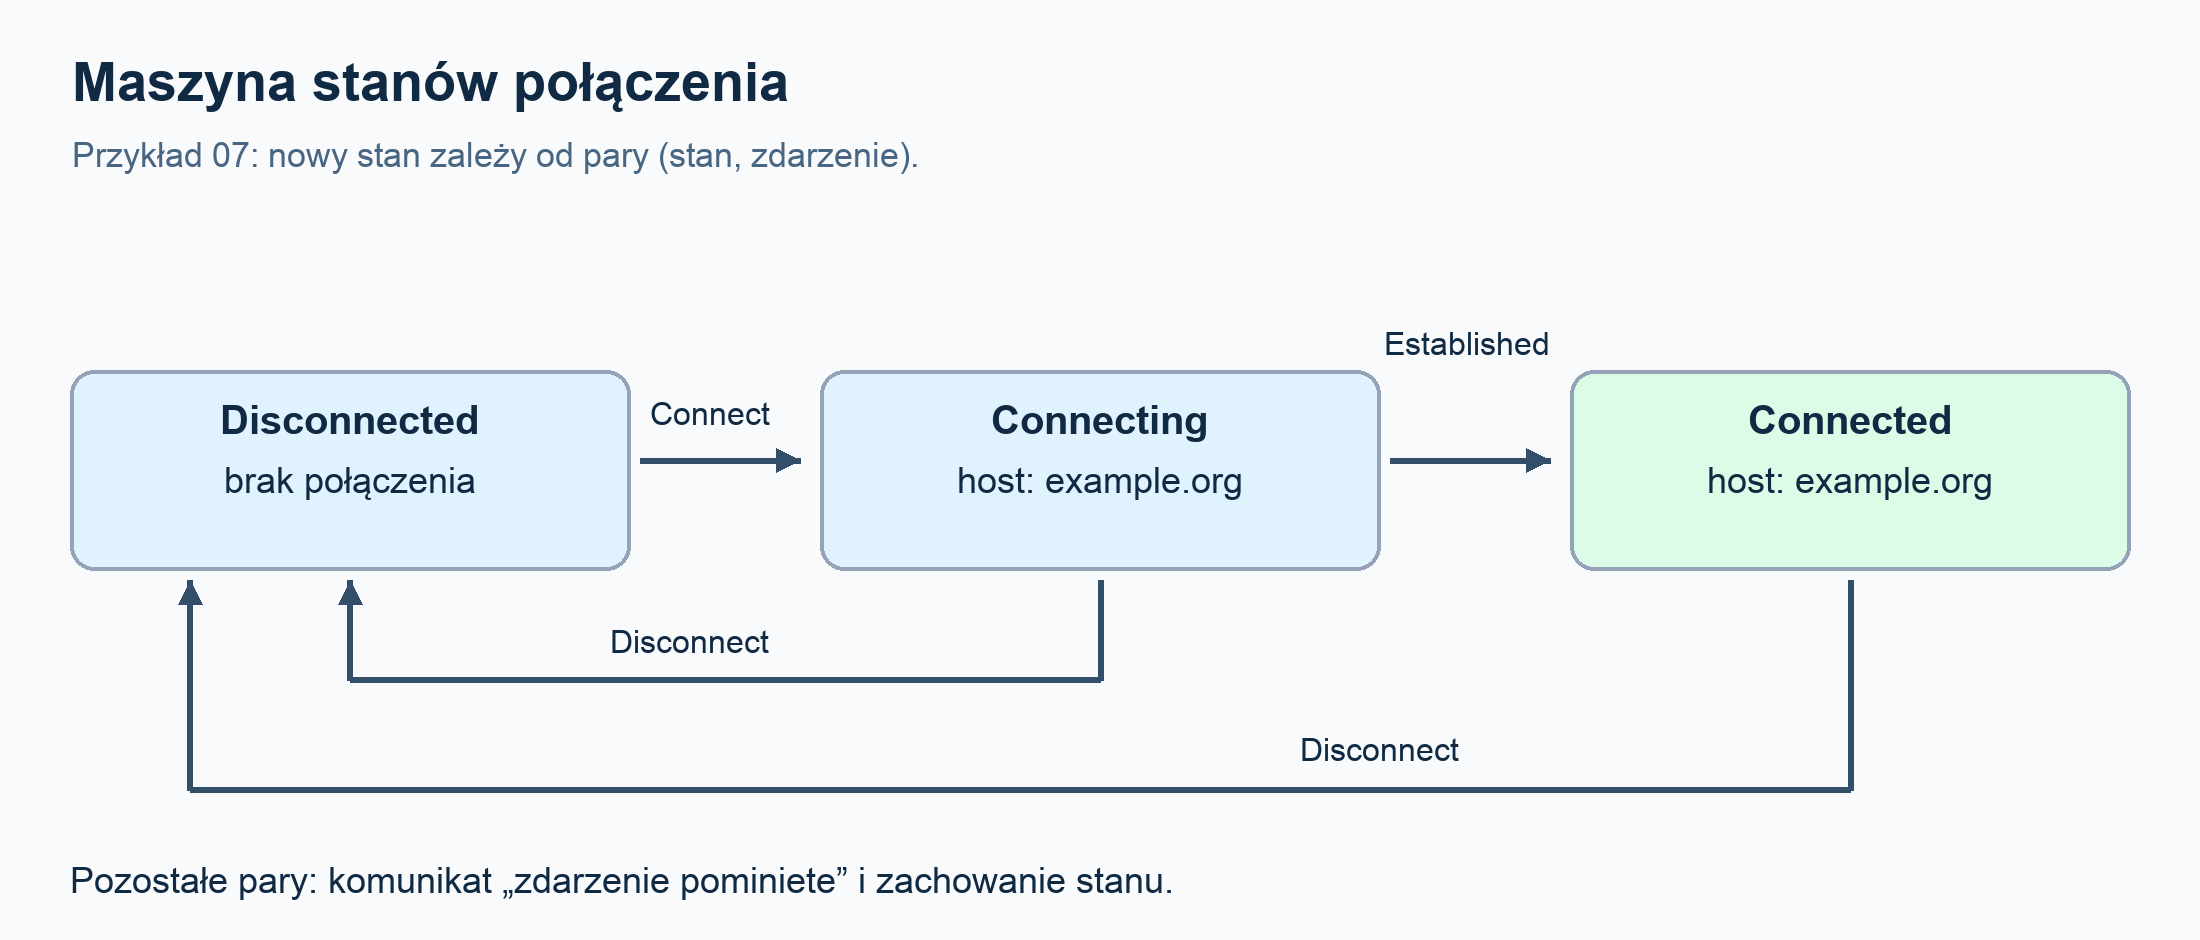

Strzałki pokazują cztery jawne reguły z `transition`. Pozostałe kombinacje obsługuje ostatnia, ogólna lambda, która zachowuje dotychczasowy stan.

#### Ta sama informacja może mieć różny sens w różnych stanach

Jeśli jesteśmy w `Connecting` i przychodzi `Established`, przechodzimy do `Connected`. Jeśli jesteśmy w `Disconnected` i przychodzi `Established`, ignorujemy to zdarzenie: nie rozpoczęliśmy wcześniej łączenia.

Funkcja `transition` przyjmuje stan i zdarzenie, a zwraca nowy stan. Poniższa komórka wyodrębnia jedną regułę: potwierdzenie połączenia w stanie `Connecting`.


In [33]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

struct Disconnected {};
struct Connecting {
    std::string host;
};
struct Connected {
    std::string host;
};
struct Established {};
using State = std::variant<Disconnected, Connecting, Connected>;

int main() {
    const auto establish = [](const Connecting& stan, const Established&) -> State {
        return Connected{stan.host};
    };
    const State state = establish(Connecting{"example.org"}, Established{});
    std::cout << std::get<Connected>(state).host << '\n';
}


example.org


Lambda `establish` pokazuje jedną z reguł odwiedzającego. Komórka zawiera też definicje typów oraz wywołanie tej lambdy. Pierwszy argument mówi, w jakim stanie jesteśmy. Drugi mówi, jakie zdarzenie obsługujemy; nie ma nazwy, ponieważ nie potrzebujemy z niego żadnych danych. `-> State` określa wspólny typ wyniku. Zwracamy stan połączenia z tym samym hostem.

W `std::visit(visitor, state, event)` odwiedzający dostaje **dwa argumenty**: wartość z wariantu stanu i wartość z wariantu zdarzenia. Ponieważ każdy wariant ma trzy możliwości, istnieje `3 × 3 = 9` kombinacji typów argumentów. Kod musi umieć obsłużyć każdą, chociaż jedno wywołanie przetwarza tylko aktualną parę.

#### Co z kombinacjami bez własnej reguły?

Program ma ogólną lambdę przyjmującą `const auto&` dla obu argumentów. Obsługuje ona pozostałe kombinacje: wypisuje `zdarzenie pominiete` i zwraca dotychczasowy stan.

Wszystkie gałęzie zwracają `State`. Dzięki temu `visit` ma jeden typ wyniku, mimo że poszczególne reguły tworzą różne struktury stanów.

#### Jak przeczytać wynik programu?

Program wykonuje kolejno:

1. Startuje w stanie `Disconnected`.
2. Dostaje `Established` za wcześnie - pomija zdarzenie.
3. Dostaje `Connect` z hostem `example.org` - przechodzi do `Connecting`.
4. Dostaje `Established` - przechodzi do `Connected`.
5. Dostaje kolejne `Connect` podczas istniejącego połączenia - pomija zdarzenie.
6. Dostaje `Disconnect` - wraca do `Disconnected`.

Instrukcja `state = transition(state, event)` najpierw oblicza nowy stan, a dopiero potem zastępuje nim dotychczasowy. Dzięki temu odwiedzający może korzystać ze starego stanu przez cały czas obliczania przejścia.

Przy dodawaniu stanów lub zdarzeń trzeba przejrzeć reguły ponownie. Ogólna lambda zapewnia poprawność wywołania dla pozostałych par, ale nie oceni za nas, czy pominięcie nowego zdarzenia ma sens. Więcej alternatyw oznacza więcej kombinacji do rozważenia i może zwiększyć czas kompilacji.

Ten program jest symulacją reguł. Nie nawiązuje rzeczywistego połączenia sieciowego.


#### Demonstracja: Przejścia między stanami połączenia

Wykonaj komórkę, aby prześledzić stan po każdym zdarzeniu oraz zobaczyć, które zdarzenia są pomijane.


In [34]:
%%cpp
// Cel: przejścia stanów jako funkcja (stan, zdarzenie) -> nowy stan.
#include <iostream>
#include <string>
#include <variant>

struct Disconnected {};
struct Connecting {
    std::string host;
};
struct Connected {
    std::string host;
};
using State = std::variant<Disconnected, Connecting, Connected>;
struct Connect {
    std::string host;
};
struct Established {};
struct Disconnect {};
using Event = std::variant<Connect, Established, Disconnect>;

template <class... Ts>
struct overloaded : Ts... {
    using Ts::operator()...;
};
template <class... Ts>
overloaded(Ts...) -> overloaded<Ts...>;

State transition(const State& state, const Event& event) {
    return std::visit(
        overloaded{
            [](const Disconnected&, const Connect& e) -> State {
                return Connecting{e.host};
            },
            [](const Connecting& s, const Established&) -> State {
                return Connected{s.host};
            },
            [](const Connecting&, const Disconnect&) -> State {
                return Disconnected{};
            },
            [](const Connected&, const Disconnect&) -> State {
                return Disconnected{};
            },
            [](const auto& s, const auto&) -> State {
                std::cout << "zdarzenie pominiete\n";
                return s;
            }
        },
        state,
        event
    );
}

void print_state(const State& state) {
    std::visit(
        overloaded{
            [](const Disconnected&) {
                std::cout << "stan: rozlaczony\n";
            },
            [](const Connecting& s) {
                std::cout << "stan: laczenie z " << s.host << '\n';
            },
            [](const Connected& s) {
                std::cout << "stan: polaczony z " << s.host << '\n';
            }
        },
        state
    );
}

int main() {
    State state{Disconnected{}};
    const Event events[] = {
        Established{}, Connect{"example.org"}, Established{}, Connect{"other.org"}, Disconnect{}
    };
    print_state(state);
    for (const auto& event : events) {
        // Zastepujemy stan dopiero po zakonczeniu odwiedzania.
        state = transition(state, event);
        print_state(state);
    }
}


stan: rozlaczony
zdarzenie pominiete
stan: rozlaczony
stan: laczenie z example.org
stan: polaczony z example.org
zdarzenie pominiete
stan: polaczony z example.org
stan: rozlaczony


**Jak czytać wynik:** Pierwsze `Established` zostaje pominięte, bo połączenie jeszcze się nie rozpoczęło. Następnie `Connect` i `Established` prowadzą do połączenia z example.org. Próba `Connect` w stanie `Connected` jest pomijana; `Disconnect` kończy połączenie.


### 13. Kiedy wybrać inne rozwiązanie i czego uczyć się dalej?

#### Dobierz narzędzie do tego, co chcesz opisać

`variant` przydaje się, gdy znasz listę różnych możliwości, np. „liczba albo tekst” lub „rozłączony albo łączenie albo połączony”. Wybór jednej z możliwości nazywa się też *sum type* - to nazwa modelu danych, a nie dodatkowa funkcja C++.

Inne sytuacje mogą wymagać prostszego lub innego narzędzia:

- **Liczba albo brak liczby:** `std::optional<int>`. Wszystkie obecne wartości mają jeden typ `int`.
- **Imię i wiek jednocześnie:** zwykła struktura z dwoma polami. Obie informacje są potrzebne razem.
- **Przechowanie wartości bez wpisywania listy typów w deklaracji pojemnika:** `std::any`. Obsługuje typy kopiowalne; aby odzyskać wartość, musisz znać jej typ.
- **Niskopoziomowe współdzielenie pamięci przez składowe:** `union`. Sam nie pamięta, która składowa jest aktywna, i nie zapewnia kontroli odczytu takiej jak `variant`.
- **Rodzina obiektów rozszerzana o kolejne typy w niezależnych częściach programu:** warto rozważyć wspólny interfejs i funkcje wirtualne. Wariant wymaga podania listy alternatyw w jego typie.

#### Co zmieniają nowsze standardy?

Cały uruchamialny kod w tych materiałach korzysta z C++17. Od C++20 można m.in. użyć `std::visit<R>`, aby wskazać typ wyniku odwiedzania. `R` oznacza tutaj wybrany przez programistę typ, np. `double`. W przykładach pozostajemy przy zapisie dostępnym w C++17. Przed użyciem rozszerzeń sprawdź obsługę w swojej bibliotece i kompilatorze.

#### Dalszy temat: drzewo wyrażeń

Wyrażenie `2 + 3` można opisać jako węzeł dodawania z dwoma podwyrażeniami. Każde podwyrażenie może być liczbą albo kolejnym działaniem. `variant` pasuje do tego wyboru, ale pojawia się problem rekurencji: węzeł nie może zawierać w sobie kolejnego pełnego obiektu tego samego typu bez końca.

Jednym z rozwiązań jest przechowywanie podwęzłów przez inteligentne wskaźniki. Węzeł przechowuje wtedy wskaźniki do osobnych obiektów zamiast umieszczać całą rekurencyjną strukturę bezpośrednio w swoim wnętrzu. To temat do dalszej nauki, wymagający także zrozumienia własności i czasu życia obiektów.

## Dobre praktyki do zapamiętania

- Wybieraj alternatywy opisujące znaczenie danych; nazwane struktury pomagają odróżnić podobne przypadki.
- Używaj `get_if`, gdy niezgodna alternatywa jest oczekiwaną sytuacją; `get`, gdy chcesz odczytu z kontrolą przez wyjątek.
- Stosuj `visit` do wspólnej operacji na alternatywach. Przejrzyj wszystkie przypadki po zmianie listy typów.
- Nie przechowuj wskaźników do alternatywy dłużej niż trwa jej życie.
- Odróżniaj pusty stan modelu (`monostate`) od braku wartości po wyjątku.
- Nie dodawaj alternatyw „na zapas”. Zbyt szeroki wariant utrudnia opis reguł programu.

## Dodatek: rozpoznawanie błędów kompilacji

Poniższe dwa programy są **celowo błędne**. Można je wykonać tak jak pozostałe komórki. Opcja `--expect-error` oznacza, że odrzucenie kodu przez kompilator jest tutaj oczekiwanym wynikiem. Po zastosowaniu opisanej poprawki usuń `--expect-error`, aby skompilować i uruchomić poprawiony program.

Pierwszy: typ `int` występuje dwa razy, więc nie można wybrać go przez sam typ. Poprawka: użyć `std::get<1>(value)`.


In [35]:
%%cpp --expect-error
#include <variant>
int main() {
    std::variant<int, int> value{std::in_place_index<1>, 9};
    (void)std::get<int>(value); // BLAD: typ nie jest jednoznaczny
}


Oczekiwany błąd kompilacji. Początek komunikatu kompilatora:
In file included from example.cpp:1:
In file included from /Library/Developer/CommandLineTools/SDKs/MacOSX.sdk/usr/include/c++/v1/variant:230:
/Library/Developer/CommandLineTools/SDKs/MacOSX.sdk/usr/include/c++/v1/__tuple/find_index.h:45:17: error: static assertion failed due to requirement 'value != __ambiguous': type occurs more than once in type list
   45 |   static_assert(value != __ambiguous, "type occurs more than once in type list");
      |                 ^~~~~~~~~~~~~~~~~~~~
/Library/Developer/CommandLineTools/SDKs/MacOSX.sdk/usr/include/c++/v1/__tuple/find_index.h:56:38: note: in instantiation of template class 'std::__find_detail::__find_exactly_one_checked<int, int, int>' requested here
   56 | struct __find_exactly_one_t : public __find_detail::__find_exactly_one_checked<_T1, _Args...> {};
      |                                      ^
/Library/Developer/CommandLineTools/SDKs/MacOSX.sdk/usr/include/c++/v1/varia

Drugi: gałęzie odwiedzającego mają różne typy wyniku. Poprawka: dopisać `-> double` do lambdy, aby obie instancje zwracały `double`.


In [36]:
%%cpp --expect-error
#include <type_traits>
#include <variant>
int main() {
    std::variant<int, double> value{1};
    (void)std::visit(
        [](auto x) {
            if constexpr (std::is_same_v<decltype(x), int>) {
                return 1;
            } else {
                return 1.5;
            }
        },
        value
    ); // BŁAD: wynik int albo double
}


Oczekiwany błąd kompilacji. Początek komunikatu kompilatora:
In file included from example.cpp:2:
/Library/Developer/CommandLineTools/SDKs/MacOSX.sdk/usr/include/c++/v1/variant:520:9: error: static assertion failed due to requirement '__all<false>::value': `std::visit` requires the visitor to have a single return type.
  520 |         __all<is_same_v<_Fp, _Fs>...>::value, "`std::visit` requires the visitor to have a single return type.");
      |         ^~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
/Library/Developer/CommandLineTools/SDKs/MacOSX.sdk/usr/include/c++/v1/variant:525:5: note: in instantiation of function template specialization 'std::__variant_detail::__visitation::__base::__std_visit_visitor_return_type_check<int (*)(std::__variant_detail::__visitation::__variant::__value_visitor<(lambda at example.cpp:6:9)> &&, std::__variant_detail::__base<std::__variant_detail::_Trait::_TriviallyAvailable, int, double> &), double (*)(std::__variant_detail::__visitation::__variant::__value_visi